,pm25,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
pm25,1.00,0.88,0.48,0.67,0.79,-0.15,-0.13,0.02,0.11,-0.01,-0.27
PM10,0.88,1.00,0.46,0.65,0.70,-0.11,-0.10,-0.02,0.07,-0.03,-0.18
SO2,0.48,0.46,1.00,0.50,0.54,-0.17,-0.32,0.22,-0.27,-0.04,-0.11
NO2,0.67,0.65,0.50,1.00,0.71,-0.47,-0.28,0.17,-0.03,-0.04,-0.40
CO,0.79,0.70,0.54,0.71,1.00,-0.31,-0.33,0.19,-0.06,-0.01,-0.30
O3,-0.15,-0.11,-0.17,-0.47,-0.31,1.00,0.59,-0.45,0.31,0.02,0.30
TEMP,-0.13,-0.10,-0.32,-0.28,-0.33,0.59,1.00,-0.81,0.82,0.04,0.03
PRES,0.02,-0.02,0.22,0.17,0.19,-0.45,-0.81,1.00,-0.75,-0.06,0.07
DEWP,0.11,0.07,-0.27,-0.03,-0.06,0.31,0.82,-0.75,1.00,0.09,-0.30
RAIN,-0.01,-0.03,-0.04,-0.04,-0.01,0.02,0.04,-0.06,0.09,1.00,0.02


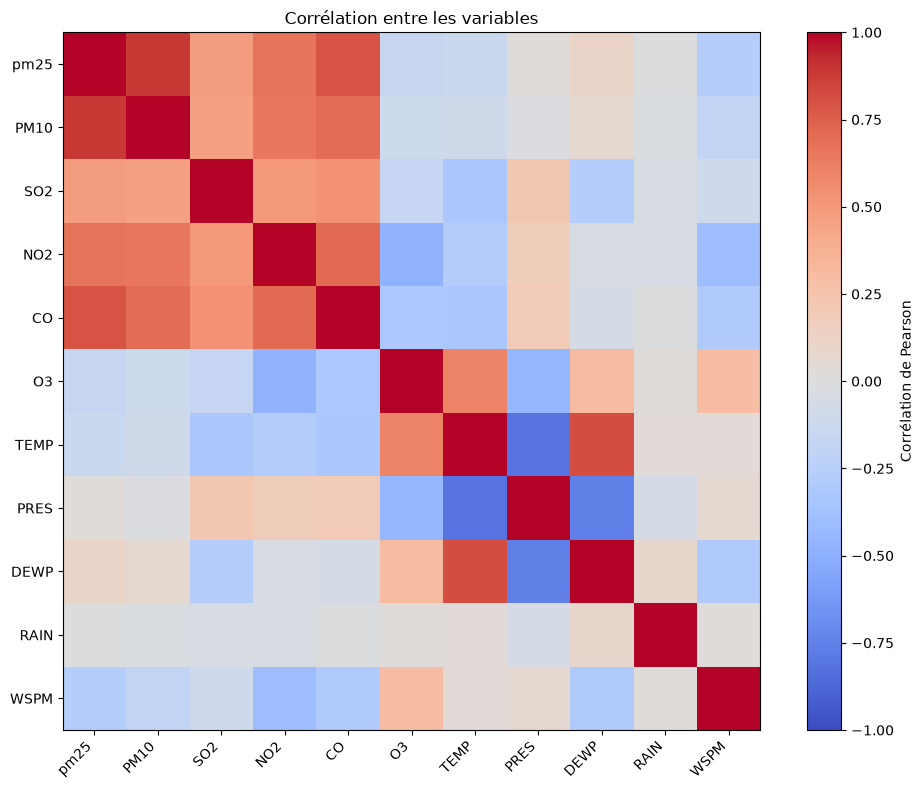

,correlation_avec_pm25
WSPM,-0.272205
O3,-0.149697
TEMP,-0.131127
RAIN,-0.014359
PRES,0.018566
DEWP,0.114656
SO2,0.482354
NO2,0.666948
CO,0.789998
PM10,0.884380


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_file = Path(
    r"C:\Users\ADMIN\Desktop\AirWatch\analytics\outputs\prepared_data\observations_clean.parquet"
)
df = pd.read_parquet(data_file)

variables = ["pm25", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
available = [column for column in variables if column in df.columns]

corr = df[available].corr(method="pearson")
display(corr.round(2))

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(image, ax=ax, label="Corrélation de Pearson")

ax.set_xticks(range(len(available)), labels=available, rotation=45, ha="right")
ax.set_yticks(range(len(available)), labels=available)
ax.set_title("Corrélation entre les variables")
fig.tight_layout()
plt.show()

pm25_correlations = corr["pm25"].drop("pm25").sort_values()
display(pm25_correlations.to_frame("correlation_avec_pm25"))